### Analyse

A faire :
- EDA avec graphiques
    - Histogrammes
    - Boîtes à moustache
    - Histogramme comparé par série
    - Histogramme comparé par plateforme
- Moyenne avec intervalles de confiance
- Ecart-type

In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns

In [ ]:
df = pd.read_csv("df_clean.csv")
df

,avis,dates,series,notes,plateforme
0,"Un début de saison (Ép. 01) très réussi, qui t...",2026-02-19,A Knight of the Seven Kingdoms,10.0,Allocine
1,J’y ai trouvé du génie ! Pour ceux qui disent ...,2026-02-07,A Knight of the Seven Kingdoms,10.0,Allocine
2,Quelle drôle d’idée de faire un schema aussi c...,2026-02-24,A Knight of the Seven Kingdoms,7.0,Allocine
3,Seule le format est décevant. Seulement 6 épis...,2026-02-08,A Knight of the Seven Kingdoms,9.0,Allocine
4,Je ne suis probablement pas très objectif conc...,2026-02-08,A Knight of the Seven Kingdoms,8.0,Allocine
...,...,...,...,...,...
1602,Mediocre filmmaking - Weak script in combinati...,2025-10-29,King & Conqueror,1.0,Imdb
1603,drunk history - As many other reviewers have n...,2026-02-02,King & Conqueror,3.0,Imdb
1604,I get it... -,2026-02-26,King & Conqueror,7.0,Imdb
1605,Realism... - Earl's military crews count 5-8 s...,2026-03-02,King & Conqueror,3.0,Imdb


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1607 entries, 0 to 1606
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   avis        1607 non-null   object 
 1   dates       1607 non-null   object 
 2   series      1607 non-null   object 
 3   notes       1607 non-null   float64
 4   plateforme  1607 non-null   object 
dtypes: float64(1), object(4)
memory usage: 62.9+ KB


In [21]:
print(df['series'].value_counts(), '\n')
print(df['series'].value_counts(normalize=True))

series
A Knight of the Seven Kingdoms    1404
King & Conqueror                   203
Name: count, dtype: int64 

series
A Knight of the Seven Kingdoms    0.873678
King & Conqueror                  0.126322
Name: proportion, dtype: float64


In [ ]:
print(df['plateforme'].value_counts(), '\n')
print(df['plateforme'].value_counts(normalize=True))

# Prépondérance importante de la plateforme Imdb

plateforme
Imdb        1412
Allocine     195
Name: count, dtype: int64 

plateforme
Imdb        0.878656
Allocine    0.121344
Name: proportion, dtype: float64


In [24]:
display(pd.crosstab(df['series'], df['plateforme']))
print()
display(pd.crosstab(df['series'], df['plateforme'], normalize=True))

# Prépondérance importante de la plateforme Imdb

plateforme,Allocine,Imdb
series,,
A Knight of the Seven Kingdoms,165,1239
King & Conqueror,30,173


plateforme,Allocine,Imdb
series,,
A Knight of the Seven Kingdoms,0.102676,0.771002
King & Conqueror,0.018668,0.107654


In [ ]:
display(df.describe())
print()
print('Statistiques sur la plateforme Allociné :\n', df[df['plateforme'] == 'Allocine'].describe() )
print()
print('Statistiques sur la plateforme Imdb :\n', df[df['plateforme'] == 'Imdb'].describe())

# Différences importantes de notation entre allociné et imdb : imdb note nettement plus haut 
# Différence de public ou de pays (fr vs usa) ?

,notes
count,1607.000000
mean,7.794648
std,3.041047
min,1.000000
25%,6.000000
50%,9.000000
75%,10.000000
max,10.000000



Statistiques sur la plateforme Allociné :
             notes
count  195.000000
mean     6.620513
std      3.010221
min      1.000000
25%      4.000000
50%      7.000000
75%      9.000000
max     10.000000

Statistiques sur la plateforme Imdb :
              notes
count  1412.000000
mean      7.956799
std       3.010537
min       1.000000
25%       7.000000
50%      10.000000
75%      10.000000
max      10.000000


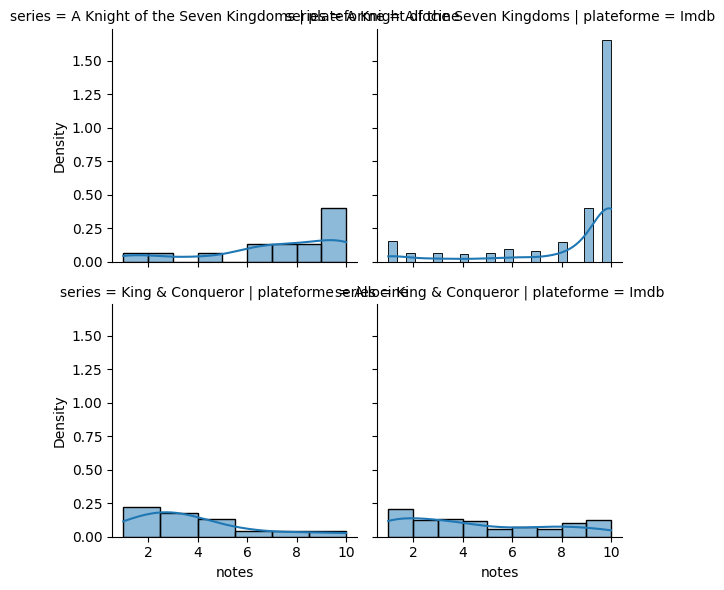

In [43]:
# Regardons de plus près les distributions

g = sns.FacetGrid(df, col="plateforme", row='series')
g.map(sns.histplot, "notes", stat='density', kde=True);

In [ ]:
sns.histplot(data=df[df['plateforme'] == 'imbs'], x='notes', bins=10, kde=True)